In [1]:
# Step 1: Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [46]:
import pandas as pd

file_path = '/content/drive/MyDrive/MS_AIML/5_QM_640_Capstone_Project/default_of_credit_card_clients/default_of_credit_card_clients_csv.csv'

# Read dataset (space-delimited)
df = pd.read_csv(file_path)

print(df.head())
print(df.info())

  Unnamed: 0         X1   X2         X3        X4   X5     X6     X7     X8  \
0         ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3   
1          1      20000    2          2         1   24      2      2     -1   
2          2     120000    2          2         2   26     -1      2      0   
3          3      90000    2          2         2   34      0      0      0   
4          4      50000    2          2         1   37      0      0      0   

      X9  ...        X15        X16        X17       X18       X19       X20  \
0  PAY_4  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3   
1     -1  ...          0          0          0         0       689         0   
2      0  ...       3272       3455       3261         0      1000      1000   
3      0  ...      14331      14948      15549      1518      1500      1000   
4      0  ...      28314      28959      29547      2000      2019      1200   

        X21       X22       X23             

### Data Pre-processing

In [47]:
print(df.isnull().sum())

Unnamed: 0    0
X1            0
X2            0
X3            0
X4            0
X5            0
X6            0
X7            0
X8            0
X9            0
X10           0
X11           0
X12           0
X13           0
X14           0
X15           0
X16           0
X17           0
X18           0
X19           0
X20           0
X21           0
X22           0
X23           0
Y             0
dtype: int64


- Dataset doesn't contain NULL values

In [48]:
print(df.duplicated().sum())

0


- Dataset doesn't contain any duplicate values.

In [49]:
columns = ["ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
           "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
           "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6", "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6", "DEFAULT_NEXT_MONTH"]
df.columns = columns
print(df.head())


   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0  ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4   
1   1      20000    2          2         1   24      2      2     -1     -1   
2   2     120000    2          2         2   26     -1      2      0      0   
3   3      90000    2          2         2   34      0      0      0      0   
4   4      50000    2          2         1   37      0      0      0      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3   
1  ...          0          0          0         0       689         0   
2  ...       3272       3455       3261         0      1000      1000   
3  ...      14331      14948      15549      1518      1500      1000   
4  ...      28314      28959      29547      2000      2019      1200   

   PAY_AMT4  PAY_AMT5  PAY_AMT6          DEFAULT_NEXT_MONTH  
0  PAY_AMT4  PAY_AMT5  P

In [50]:
print(df.isnull().sum())

ID                    0
LIMIT_BAL             0
SEX                   0
EDUCATION             0
MARRIAGE              0
AGE                   0
PAY_0                 0
PAY_2                 0
PAY_3                 0
PAY_4                 0
PAY_5                 0
PAY_6                 0
BILL_AMT1             0
BILL_AMT2             0
BILL_AMT3             0
BILL_AMT4             0
BILL_AMT5             0
BILL_AMT6             0
PAY_AMT1              0
PAY_AMT2              0
PAY_AMT3              0
PAY_AMT4              0
PAY_AMT5              0
PAY_AMT6              0
DEFAULT_NEXT_MONTH    0
dtype: int64


- No NULL value present

In [51]:
import pandas as pd

# Check data types
print(df.dtypes)

# Inspect unique values for categorical variables
print("SEX:", df['SEX'].unique())
print("EDUCATION:", df['EDUCATION'].unique())
print("MARRIAGE:", df['MARRIAGE'].unique())
print("PAY_0:", df['PAY_0'].unique())

# Encode categorical variables
# SEX: keep numeric
# SEX: keep numeric
df['SEX'] = pd.to_numeric(df['SEX'], errors='coerce')
df['SEX'] = df['SEX'].map({1:0, 2:1})   # optional binary encoding

# EDUCATION anomalies
df['EDUCATION'] = df['EDUCATION'].replace({0:4, 5:4, 6:4})

# MARRIAGE anomalies
df['MARRIAGE'] = df['MARRIAGE'].replace({0:3})

# Drop any rows where SEX is NaN (caused by header row slip)
df = df.dropna(subset=['SEX'])

# Repayment status (PAY_0 to PAY_6): already ordinal, but check ranges
for col in ['PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']:
    print(col, df[col].unique())


ID                    object
LIMIT_BAL             object
SEX                   object
EDUCATION             object
MARRIAGE              object
AGE                   object
PAY_0                 object
PAY_2                 object
PAY_3                 object
PAY_4                 object
PAY_5                 object
PAY_6                 object
BILL_AMT1             object
BILL_AMT2             object
BILL_AMT3             object
BILL_AMT4             object
BILL_AMT5             object
BILL_AMT6             object
PAY_AMT1              object
PAY_AMT2              object
PAY_AMT3              object
PAY_AMT4              object
PAY_AMT5              object
PAY_AMT6              object
DEFAULT_NEXT_MONTH    object
dtype: object
SEX: ['SEX' '2' '1']
EDUCATION: ['EDUCATION' '2' '1' '3' '5' '4' '6' '0']
MARRIAGE: ['MARRIAGE' '1' '2' '3' '0']
PAY_0: ['PAY_0' '2' '-1' '0' '-2' '1' '3' '4' '8' '7' '5' '6']
PAY_0 ['2' '-1' '0' '-2' '1' '3' '4' '8' '7' '5' '6']
PAY_2 ['2' '0' '-1' '-2' '3' '5

- Confirms data types.

- Shows unique values for categorical variables.

- Cleans anomalies in EDUCATION (values 0, 5, 6 → “Others”) and MARRIAGE (value 0 → “Others”).

- Maps SEX into readable labels.

- Validates repayment status ranges (−2 to 9).

In [52]:
num_cols = ['LIMIT_BAL','BILL_AMT1','BILL_AMT2','BILL_AMT3',
            'BILL_AMT4','BILL_AMT5','BILL_AMT6',
            'PAY_AMT1','PAY_AMT2','PAY_AMT3',
            'PAY_AMT4','PAY_AMT5','PAY_AMT6']

# Convert to numeric, invalid entries become NaN
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')

# Drop rows with NaN in these columns
df = df.dropna(subset=num_cols)

# Now safe to compute outliers
from scipy import stats
outlier_counts = {col: (abs(stats.zscore(df[col])) > 3).sum() for col in num_cols}

print("Outlier counts per column:")
print(outlier_counts)


Outlier counts per column:
{'LIMIT_BAL': np.int64(130), 'BILL_AMT1': np.int64(686), 'BILL_AMT2': np.int64(670), 'BILL_AMT3': np.int64(661), 'BILL_AMT4': np.int64(680), 'BILL_AMT5': np.int64(651), 'BILL_AMT6': np.int64(651), 'PAY_AMT1': np.int64(390), 'PAY_AMT2': np.int64(307), 'PAY_AMT3': np.int64(362), 'PAY_AMT4': np.int64(396), 'PAY_AMT5': np.int64(414), 'PAY_AMT6': np.int64(439)}


In [53]:
# Handle Outliers
# Scale numeric variables
from sklearn.preprocessing import RobustScaler

# Continuous variables
numeric_cols = ['LIMIT_BAL','BILL_AMT1','BILL_AMT2','BILL_AMT3',
            'BILL_AMT4','BILL_AMT5','BILL_AMT6',
            'PAY_AMT1','PAY_AMT2','PAY_AMT3',
            'PAY_AMT4','PAY_AMT5','PAY_AMT6']

# Initialize RobustScaler (less sensitive to outliers)
scaler = RobustScaler()

# Fit and transform
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

# Quick check: scaled summary
print(df[numeric_cols].describe())


          LIMIT_BAL     BILL_AMT1     BILL_AMT2     BILL_AMT3     BILL_AMT4  \
count  30000.000000  30000.000000  30000.000000  30000.000000  30000.000000   
mean       0.144654      0.453972      0.458512      0.468267      0.463996   
std        0.682882      1.159031      1.166372      1.206108      1.232920   
min       -0.684211     -2.958521     -1.490901     -3.084472     -3.623126   
25%       -0.473684     -0.296271     -0.298505     -0.303004     -0.320535   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        0.526316      0.703729      0.701495      0.696996      0.679465   
max        4.526316     14.829154     15.776915     28.592059     16.721858   

          BILL_AMT5     BILL_AMT6      PAY_AMT1      PAY_AMT2      PAY_AMT3  \
count  30000.000000  30000.000000  30000.000000  30000.000000  30000.000000   
mean       0.458560      0.454730      0.889561      0.938844      0.832486   
std        1.255426      1.242205      4.134618    

In [74]:
#Feature Engineering

import numpy as np

# Safe ratio calculation: avoid division by zero
for i in range(1, 7):
    # Payment-to-Bill Ratio
    df[f'PAY_RATIO{i}'] = np.where(df[f'BILL_AMT{i}'] > 1e-6,   # tiny threshold
                                   df[f'PAY_AMT{i}'] / df[f'BILL_AMT{i}'],
                                   0)
    # Clip extreme ratios to a reasonable bound (e.g., 0–5)
    df[f'PAY_RATIO{i}'] = df[f'PAY_RATIO{i}'].clip(0, 5)

    # Utilization Ratio
    df[f'UTIL_RATIO{i}'] = np.where(df['LIMIT_BAL'] > 1e-6,
                                    df[f'BILL_AMT{i}'] / df['LIMIT_BAL'],
                                    0)
    # Clip utilization to 0–5 (500% usage cap)
    df[f'UTIL_RATIO{i}'] = df[f'UTIL_RATIO{i}'].clip(0, 5)

# After feature engineering, replace any residual inf/-inf with NaN and impute
df = df.replace([np.inf, -np.inf], np.nan)
df = df.fillna(0)   # or use median imputation if preferred


# Quick check: engineered features
print(df[['TOTAL_BILL','TOTAL_PAY','AVG_PAY_RATIO','BILL_TREND','PAY_TREND',
          'MISSED_PAYMENTS','OVERPAYMENTS']].head())

   TOTAL_BILL  TOTAL_PAY  AVG_PAY_RATIO  BILL_TREND  PAY_TREND  \
1   -2.019718  -2.465241       0.000000   -0.065379   0.137840   
2   -1.824928  -1.363412       0.000000    0.022016   0.653005   
3   -0.310574   0.172878      -0.224331   -0.139684   1.046821   
4    2.000102  -0.518820      -0.326016   -0.127109  -0.103829   
5   -0.096637  11.879900       8.022933    0.259622  -0.186513   

   MISSED_PAYMENTS  OVERPAYMENTS  
1                0             0  
2                0             4  
3                0             1  
4                0             0  
5                0             4  


In [75]:
print(df[numeric_cols].dtypes)
print(df[numeric_cols].head())

LIMIT_BAL    float64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
dtype: object
   LIMIT_BAL  BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  \
1  -0.631579  -0.290695  -0.296584  -0.337391  -0.365126  -0.373848   
2  -0.105263  -0.310071  -0.319150  -0.302730  -0.302419  -0.302504   
3  -0.263158   0.107937  -0.117549  -0.113559  -0.090477  -0.065180   
4  -0.473684   0.387339   0.443008   0.507883   0.177504   0.224139   
5  -0.473684  -0.216654  -0.254500   0.273859   0.036183   0.021506   

   BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6  
1  -0.356074 -0.524214 -0.316775 -0.437424 -0.403524 -0.396930 -0.386374  
2  -0.288055 -0.524214 -0.242141 -0.194411 -0.134508 -0.396930  0.128791  
3  -0.031747 -0.145282 -0.122150 -0.194411 -0.134508 -0.13231

In [76]:
df = df.rename(columns={"DEFAULT_NEXT_MONTH": "CreditRisk"})

CreditRisk
0    23364
1     6636
Name: count, dtype: int64
CreditRisk
0    0.7788
1    0.2212
Name: count, dtype: float64


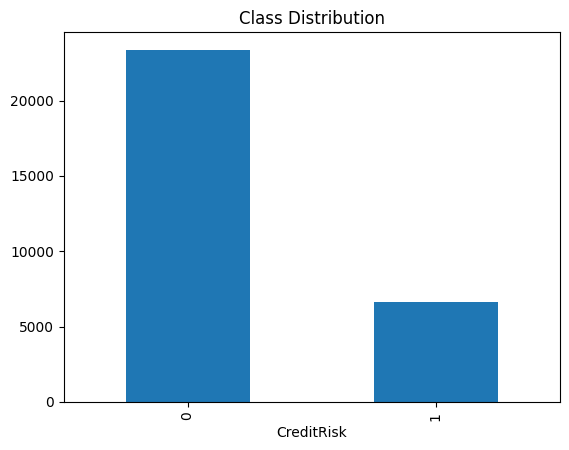

In [77]:
#Class Imbalance Check
import matplotlib.pyplot as plt

# Target distribution
class_counts = df['CreditRisk'].value_counts()
print(class_counts)

# Percentage distribution
print(class_counts / len(df))

# Quick bar plot
class_counts.plot(kind='bar', title='Class Distribution')
plt.show()


In [78]:
# Step 1: Clean target column
df["CreditRisk"] = pd.to_numeric(df["CreditRisk"], errors="coerce")

df = df.dropna(subset=["CreditRisk"])
df["CreditRisk"] = df["CreditRisk"].astype(int)

# Step 2: Rename to meaningful name
#df = df.rename(columns={"DEFAULT_NEXT_MONTH": "CreditRisk"})


print(df["CreditRisk"].value_counts())

CreditRisk
0    23364
1     6636
Name: count, dtype: int64


In [85]:
import numpy as np
import pandas as pd

# Force all columns to numeric (anything non-numeric becomes NaN)
df_numeric = df.apply(pd.to_numeric, errors="coerce")

# Check for infinities
inf_mask = np.isinf(df_numeric.to_numpy())
print("Total infinities:", inf_mask.sum())
#print("Infinities per column:\n", pd.Series(inf_mask.sum(axis=0), index=df_numeric.columns))

# Check for NaNs
nan_mask = np.isnan(df_numeric.to_numpy())
print("Total NaNs:", nan_mask.sum())
#print("NaNs per column:\n", pd.Series(nan_mask.sum(axis=0), index=df_numeric.columns))

# Identify problematic rows
bad_rows = np.where(inf_mask.any(axis=1) | nan_mask.any(axis=1))[0]
print("Rows with issues:", bad_rows[:20])  # show first 20


Total infinities: 0
Total NaNs: 0
Rows with issues: []


In [86]:
# Step 5: Train/Test split
from sklearn.model_selection import train_test_split

# Target variable: DEFAULT_NEXT_MONTH (already binary: 0 = Non-default, 1 = Default)
X = df.drop(columns=["ID","CreditRisk"])   # drop ID and target
y = df["CreditRisk"]

# Check distribution
print("Class distribution:\n", y.value_counts())

# Train/Test split (stratified to preserve class distribution ~22% default)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

Class distribution:
 CreditRisk
0    23364
1     6636
Name: count, dtype: int64


In [87]:
print("Missing values per column:\n", X.isnull().sum())


Missing values per column:
 LIMIT_BAL          0
SEX                0
EDUCATION          0
MARRIAGE           0
AGE                0
PAY_0              0
PAY_2              0
PAY_3              0
PAY_4              0
PAY_5              0
PAY_6              0
BILL_AMT1          0
BILL_AMT2          0
BILL_AMT3          0
BILL_AMT4          0
BILL_AMT5          0
BILL_AMT6          0
PAY_AMT1           0
PAY_AMT2           0
PAY_AMT3           0
PAY_AMT4           0
PAY_AMT5           0
PAY_AMT6           0
PAY_RATIO1         0
UTIL_RATIO1        0
PAY_RATIO2         0
UTIL_RATIO2        0
PAY_RATIO3         0
UTIL_RATIO3        0
PAY_RATIO4         0
UTIL_RATIO4        0
PAY_RATIO5         0
UTIL_RATIO5        0
PAY_RATIO6         0
UTIL_RATIO6        0
TOTAL_BILL         0
TOTAL_PAY          0
AVG_PAY_RATIO      0
BILL_TREND         0
PAY_TREND          0
MISSED_PAYMENTS    0
OVERPAYMENTS       0
dtype: int64


### Base Model

In [88]:
# Step 6: Baseline Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

- Reasoning: Logistic Regression is a baseline, interpretable, widely used in credit scoring.

- Assumptions: Linear relationship between predictors and log‑odds of default.

- Limitations: Sensitive to multicollinearity, may underperform on nonlinear patterns.

In [89]:
# Step 7: Evaluation
from sklearn.metrics import accuracy_score

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
acc = accuracy_score(y_test, y_pred)
print("\nAccuracy:", round(acc, 2))

Confusion Matrix:
 [[6799  210]
 [1522  469]]

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.97      0.89      7009
           1       0.69      0.24      0.35      1991

    accuracy                           0.81      9000
   macro avg       0.75      0.60      0.62      9000
weighted avg       0.79      0.81      0.77      9000


Accuracy: 0.81


### EDAs

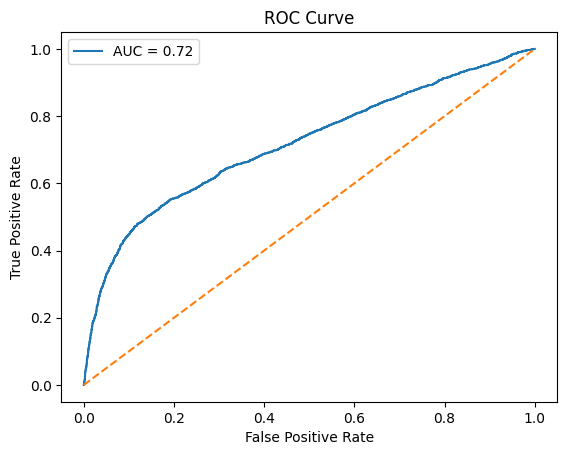

In [90]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = model.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


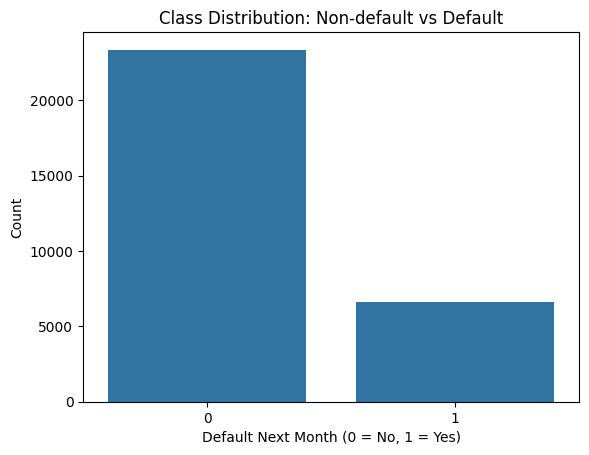

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Class balance
sns.countplot(x="CreditRisk", data=df)
plt.title("Class Distribution: Non-default vs Default")
plt.xlabel("Default Next Month (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()


- Class Distribution Bar Chart: Shows imbalance (≈22% default vs 78% non‑default). This is important for motivating class imbalance handling.

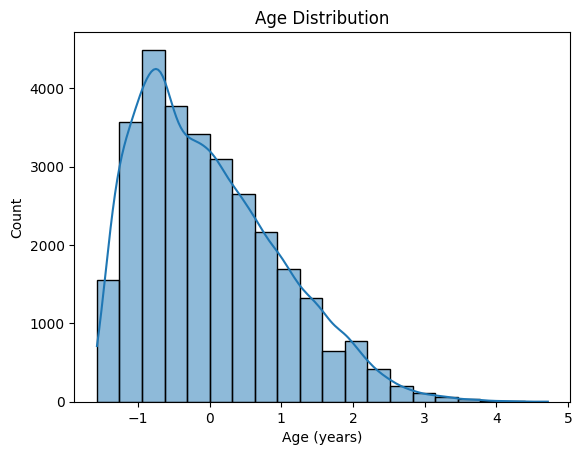

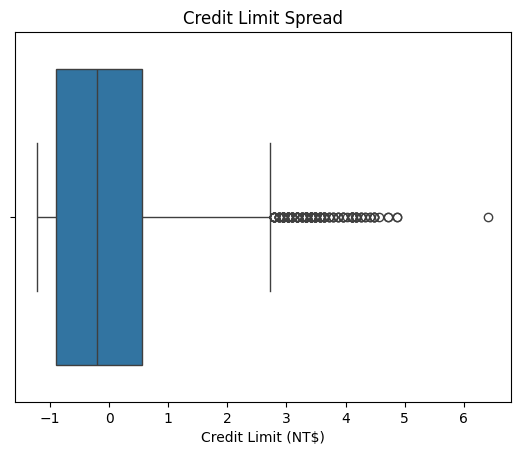

In [ ]:
# Histogram for Age
sns.histplot(df["AGE"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Count")
plt.show()

# Boxplot for Credit Amount
sns.boxplot(x=df["LIMIT_BAL"])
plt.title("Credit Limit Spread")
plt.xlabel("Credit Limit (NT$)")
plt.show()


- Age Histogram: Reveals right‑skewed distribution; younger customers dominate, older customers taper off. Supports demographic analysis.

- Credit Limit Boxplot: Highlights variability and extreme outliers in credit limits. Outliers may distort models if not handled.

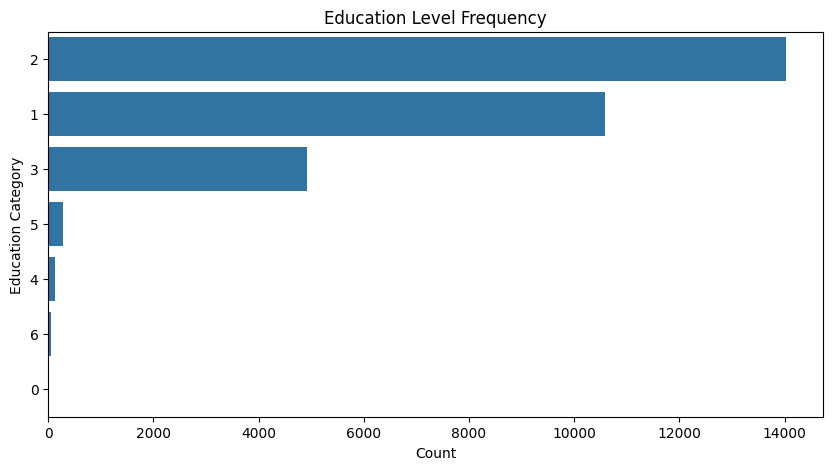

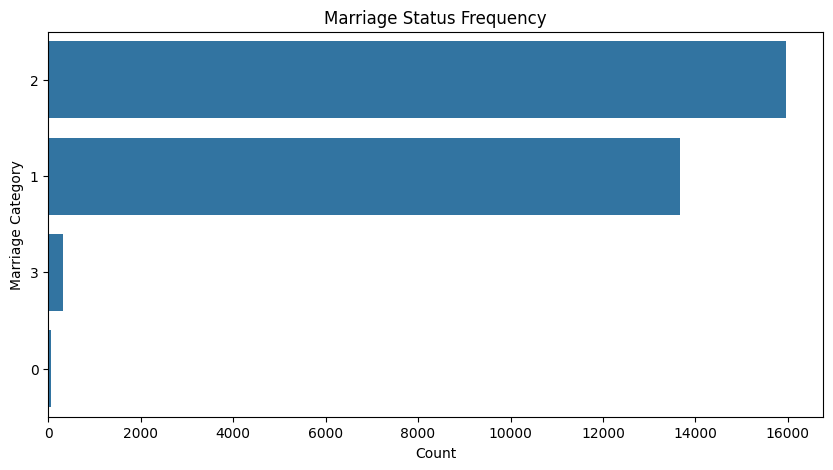

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Example: Bar plot for Education levels
plt.figure(figsize=(10,5))
sns.countplot(y="EDUCATION", data=df, order=df["EDUCATION"].value_counts().index)
plt.title("Education Level Frequency")
plt.xlabel("Count")
plt.ylabel("Education Category")
plt.show()

# Example: Bar plot for Marriage status
plt.figure(figsize=(10,5))
sns.countplot(y="MARRIAGE", data=df, order=df["MARRIAGE"].value_counts().index)
plt.title("Marriage Status Frequency")
plt.xlabel("Count")
plt.ylabel("Marriage Category")
plt.show()

- Education Frequency Chart: Most customers are in category 2 (graduate level). Rare categories (0, 4, 5, 6) may need grouping.

- Marriage Status Frequency Chart: Majority are category 2 (married), followed by category 1 (single). Rare categories again suggest grouping.

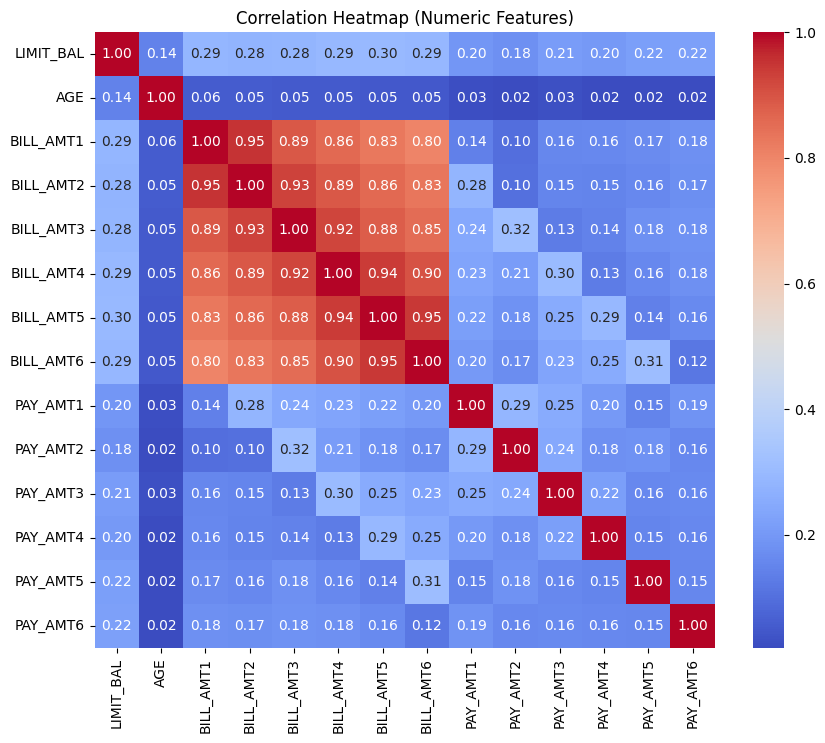

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation matrix for numeric features
numeric_cols = ["LIMIT_BAL","AGE"] + \
               [f"BILL_AMT{i}" for i in range(1,7)] + \
               [f"PAY_AMT{i}" for i in range(1,7)]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()


- Correlation Heatmap: Strong correlations among consecutive bill amounts; moderate correlations among payments. Helps identify redundant features.

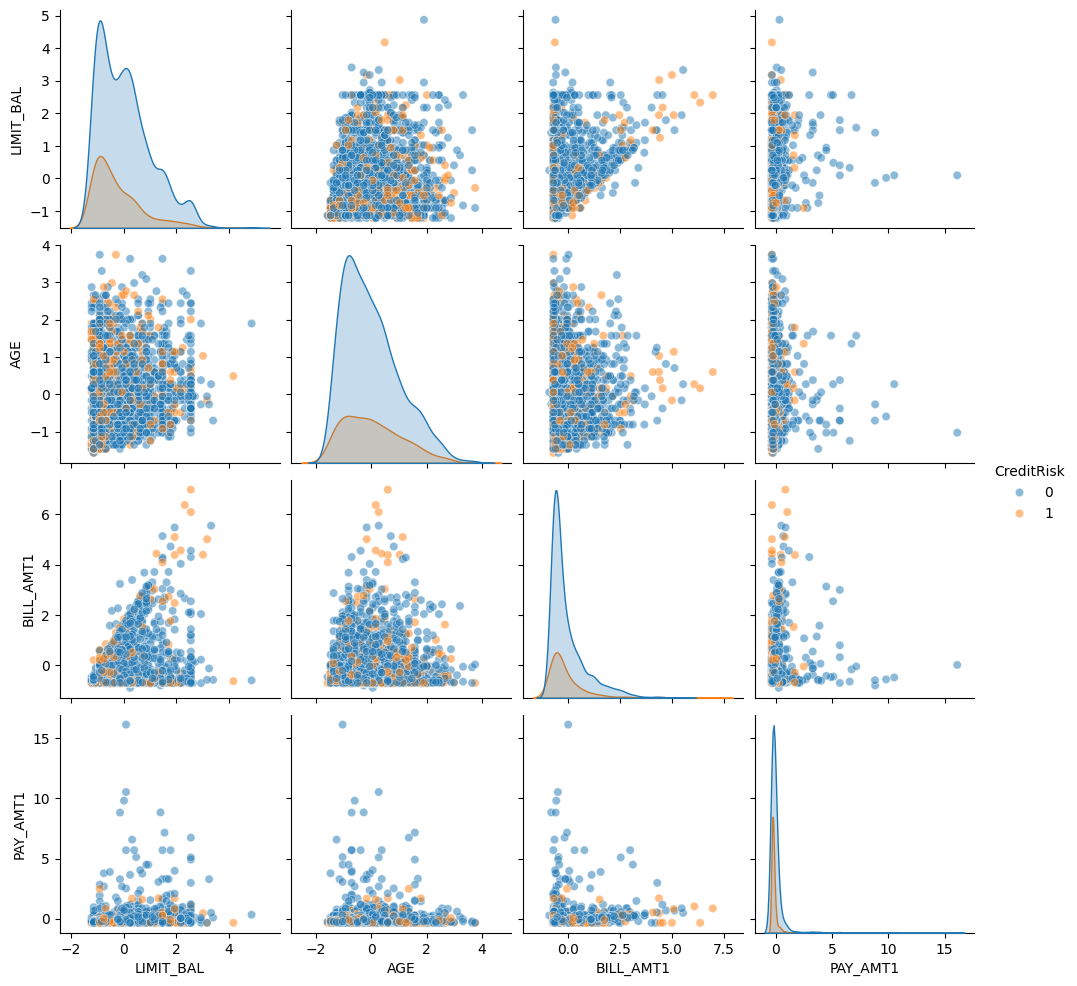

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sample subset for speed
df_sample = df.sample(2000, random_state=42)

# Shortlist of key numeric features
selected_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "CreditRisk"]

sns.pairplot(df_sample[selected_cols],
             hue="CreditRisk",
             diag_kind="kde",
             plot_kws={"alpha":0.5})
plt.show()

- Pair Plot: Shows relationships between LIMIT_BAL, AGE, BILL_AMT1, PAY_AMT1, color‑coded by default status. Reveals separation patterns and overlap between classes.

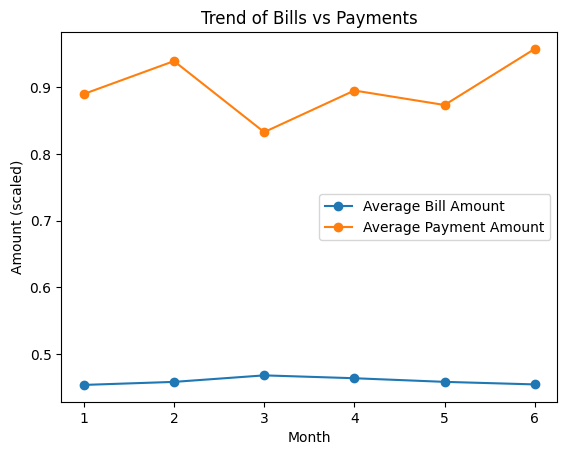

In [91]:
import matplotlib.pyplot as plt

# Average bill and payment amounts across months
avg_bills = [df[f'BILL_AMT{i}'].mean() for i in range(1,7)]
avg_pays  = [df[f'PAY_AMT{i}'].mean() for i in range(1,7)]

months = range(1,7)

plt.plot(months, avg_bills, marker='o', label='Average Bill Amount')
plt.plot(months, avg_pays, marker='o', label='Average Payment Amount')
plt.xlabel("Month")
plt.ylabel("Amount (scaled)")
plt.title("Trend of Bills vs Payments")
plt.legend()
plt.show()


Trend of Bills vs Payments (Line Plot)
- What it shows: Average bill amounts remain relatively flat across months, while average payments are consistently higher and more variable.

- Insight: This suggests that, on average, customers are paying more than their billed amounts, which could indicate proactive repayment or overpayment behavior.

- Link to research questions: Supports the question on repayment consistency and highlights a potential anomaly — payments exceeding bills — which may influence default prediction.

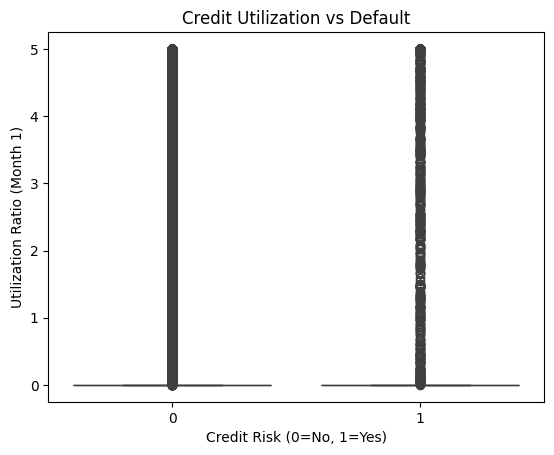

In [92]:
import seaborn as sns

sns.boxplot(x="CreditRisk", y="UTIL_RATIO1", data=df)
plt.title("Credit Utilization vs Default")
plt.xlabel("Credit Risk (0=No, 1=Yes)")
plt.ylabel("Utilization Ratio (Month 1)")
plt.show()


Credit Utilization vs Default (Box/Scatter Plot)
- What it shows: Utilization ratios (bill amount relative to credit limit) are spread across both non‑defaulters and defaulters, but defaulters tend to cluster at higher utilization levels.

- Insight: High utilization is a known risk factor — customers who consistently use a large portion of their credit limit are more likely to default.

- Link to research questions: Directly addresses predictors of default, showing utilization ratio as a strong behavioral signal.